In [11]:
import torch, torchvision
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import copy
import pandas as pd

In [ ]:
torch.manual_seed(0)

norm = transforms.Normalize(0.5, 0.5)
tf_plain = transforms.Compose([transforms.ToTensor(), norm])
tf_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(28, padding=2),
    transforms.ToTensor(),
    norm,
])

full_plain = datasets.FashionMNIST("data", train=True, download=True, transform=tf_plain)
full_aug = datasets.FashionMNIST("data", train=True, download=True, transform=tf_aug)
test_ds = datasets.FashionMNIST("data", train=False, download=True, transform=tf_plain)

g = torch.Generator().manual_seed(0)
perm = torch.randperm(60000, generator=g)
train_idx, val_idx = perm[:50000], perm[50000:]
torch.save({"train": train_idx, "val": val_idx}, "split_idx.pt")

train_plain = Subset(full_plain, train_idx)
train_aug = Subset(full_aug,   train_idx)
val_ds = Subset(full_plain, val_idx)

train_eval_loader = DataLoader(train_plain, batch_size=256, shuffle=False)
val_loader = DataLoader(val_ds, batch_size=256, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False)

In [5]:
def build_mlp(hidden_sizes, in_dim=784, out_dim=10, use_bn=False, p_drop=0.0):
    layers = [nn.Flatten()]
    prev = in_dim
    for h in hidden_sizes:
        layers.append(nn.Linear(prev, h))
        if use_bn:
            layers.append(nn.BatchNorm1d(h))
        layers.append(nn.ReLU())
        if p_drop > 0:
            layers.append(nn.Dropout(p_drop))
        prev = h
    layers.append(nn.Linear(prev, out_dim))
    return nn.Sequential(*layers)

HIDDEN = (512, 256, 128)
m = build_mlp(HIDDEN)
print(sum(p.numel() for p in m.parameters()))

567434


In [ ]:
criterion = nn.CrossEntropyLoss()

def evaluate(model, loader):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            out = model(xb)
            loss_sum += criterion(out, yb).item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            n += xb.size(0)
    return loss_sum / n, correct / n

def run(cfg, epochs=20, patience=None):
    """cfg: aug, bn, drop, wd, opt, sched, lr"""
    torch.manual_seed(0)
    model = build_mlp(HIDDEN, use_bn=cfg["bn"], p_drop=cfg["drop"])

    ds = train_aug if cfg["aug"] else train_plain
    g = torch.Generator().manual_seed(0)
    train_loader = DataLoader(ds, batch_size=64, shuffle=True, generator=g)

    if cfg["opt"] == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    elif cfg["opt"] == "adamw":
        opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    else:
        opt = torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=0.9, weight_decay=cfg["wd"])

    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs) if cfg["sched"] == "cos" else None

    hist = {k: [] for k in ["train_loss", "train_eval_loss", "train_eval_acc", "val_loss", "val_acc"]}
    best_val, best_epoch, best_state, bad = float("inf"), 0, None, 0

    for ep in range(1, epochs + 1):
        model.train()
        run_loss, n = 0.0, 0
        for xb, yb in train_loader:
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
            run_loss += loss.item() * xb.size(0)
            n += xb.size(0)
        if sched: sched.step()

        tel, tea = evaluate(model, train_eval_loader)
        vl, va = evaluate(model, val_loader)

        for k, v in zip(hist, [run_loss / n, tel, tea, vl, va]):
            hist[k].append(v)

        if vl < best_val:
            best_val, best_epoch, bad = vl, ep, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if patience and bad >= patience:
                break

    return {"cfg": cfg, "hist": hist, "best_epoch": best_epoch,
            "best_state": best_state, "model": model}

def summary(res):
    i = res["best_epoch"] - 1
    h = res["hist"]
    return {"epoka": res["best_epoch"],
            "val_loss": h["val_loss"][i],
            "val_acc": h["val_acc"][i],
            "luka": h["val_loss"][i] - h["train_eval_loss"][i]}

In [8]:
BASE = dict(aug=False, bn=False, drop=0.0, wd=0.0, opt="adam", sched=None, lr=1e-3)

res_base = run(BASE, epochs=20)
print(summary(res_base))

{'epoka': 5, 'val_loss': 0.31292776989936827, 'val_acc': 0.8883, 'luka': 0.06348943032264709}


In [ ]:
experiments = {
    "+augmentacja": {"aug": True},
    "+BatchNorm": {"bn": True},
    "+dropout 0.3": {"drop": 0.3},
    "+weight decay 1e-4": {"wd": 1e-4},
    "+scheduler cos": {"sched": "cos"},
}

results = {"baseline": res_base}

for name, change in experiments.items():
    cfg = {**BASE, **change}
    results[name] = run(cfg, epochs=20)
    print(name, summary(results[name]))

+augmentacja {'epoka': 20, 'val_loss': 0.33599654517173766, 'val_acc': 0.8749, 'luka': 0.03354399968147276}
+BatchNorm {'epoka': 9, 'val_loss': 0.30133546369075775, 'val_acc': 0.8979, 'luka': 0.147838321018219}
+dropout 0.3 {'epoka': 20, 'val_loss': 0.3113665613770485, 'val_acc': 0.8882, 'luka': 0.09443620324373245}
+weight decay 1e-4 {'epoka': 16, 'val_loss': 0.3184603788614273, 'val_acc': 0.8889, 'luka': 0.14189886476516725}
+scheduler cos {'epoka': 11, 'val_loss': 0.3113574609875679, 'val_acc': 0.8906, 'luka': 0.14739654065370558}


In [12]:
def table(results):
    rows = [{"konfiguracja": name, **summary(r)} for name, r in results.items()]
    return pd.DataFrame(rows).round(4)

base_vl = summary(results["baseline"])["val_loss"]
improved = [k for k in experiments if summary(results[k])["val_loss"] < base_vl]
print("poprawiły val_loss:", improved)

combo_cfg = dict(BASE)
for k in improved:
    combo_cfg.update(experiments[k])

results["kombinacja"] = run(combo_cfg, epochs=20)
print(table(results).to_string(index=False))

poprawiły val_loss: ['+BatchNorm', '+dropout 0.3', '+scheduler cos']
      konfiguracja  epoka  val_loss  val_acc   luka
          baseline      5    0.3129   0.8883 0.0635
      +augmentacja     20    0.3360   0.8749 0.0335
        +BatchNorm      9    0.3013   0.8979 0.1478
      +dropout 0.3     20    0.3114   0.8882 0.0944
+weight decay 1e-4     16    0.3185   0.8889 0.1419
    +scheduler cos     11    0.3114   0.8906 0.1474
        kombinacja     14    0.2662   0.9015 0.1107


In [ ]:
best_name = min(results, key=lambda k: summary(results[k])["val_loss"])
print("wybrana:", best_name)

def test_final(res):
    cfg = res["cfg"]
    m = build_mlp(HIDDEN, use_bn=cfg["bn"], p_drop=cfg["drop"])
    m.load_state_dict(res["best_state"])
    return evaluate(m, test_loader)

for name in ("baseline", best_name):
    tl, ta = test_final(results[name])
    print(f"{name}: test_loss={tl:.4f}, test_acc={ta:.4f}")

wybrana: kombinacja
baseline: test_loss=0.3373, test_acc=0.8783
kombinacja: test_loss=0.2928, test_acc=0.8987


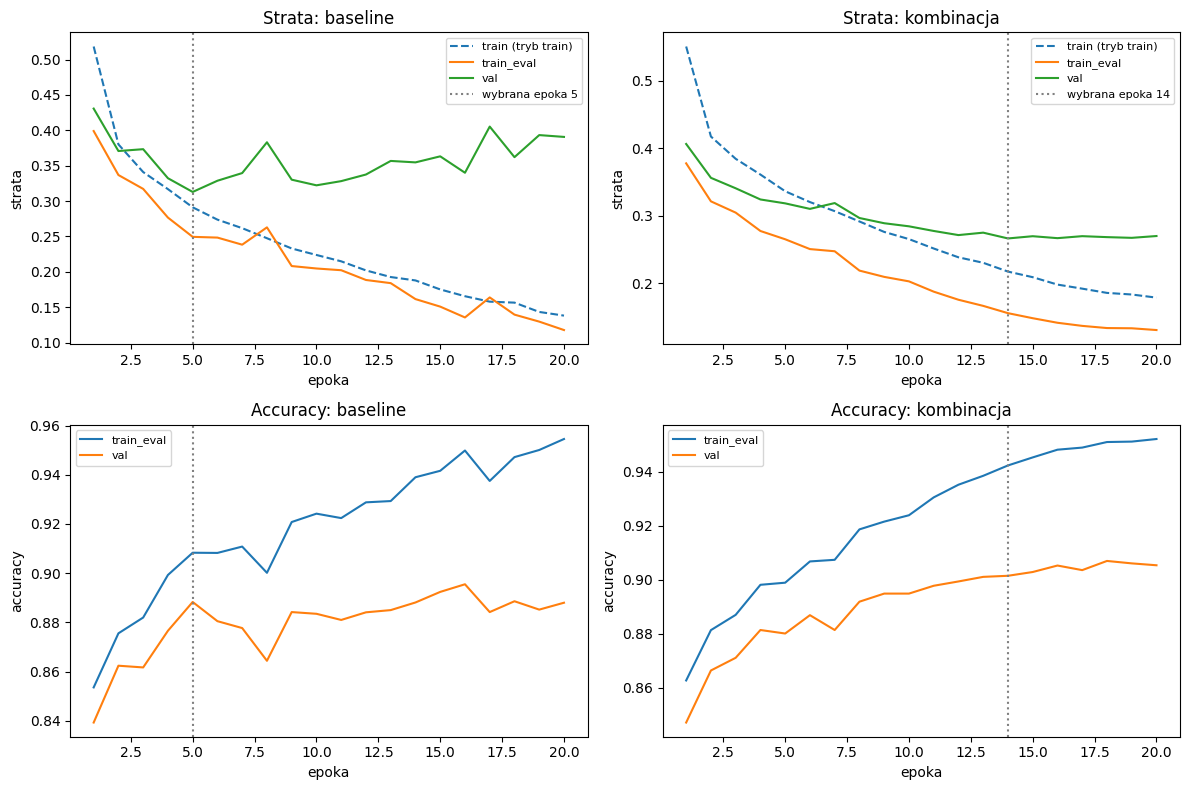

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, name in enumerate(["baseline", best_name]):
    h = results[name]["hist"]
    be = results[name]["best_epoch"]
    ep = range(1, len(h["val_loss"]) + 1)

    ax = axes[0, col]
    ax.plot(ep, h["train_loss"], "--", label="train (tryb train)")
    ax.plot(ep, h["train_eval_loss"], label="train_eval")
    ax.plot(ep, h["val_loss"], label="val")
    ax.axvline(be, color="gray", ls=":", label=f"wybrana epoka {be}")
    ax.set_title(f"Strata: {name}")
    ax.set_xlabel("epoka"); ax.set_ylabel("strata"); ax.legend(fontsize=8)

    ax = axes[1, col]
    ax.plot(ep, h["train_eval_acc"], label="train_eval")
    ax.plot(ep, h["val_acc"], label="val")
    ax.axvline(be, color="gray", ls=":")
    ax.set_title(f"Accuracy: {name}")
    ax.set_xlabel("epoka"); ax.set_ylabel("accuracy"); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("krzywe_lab2.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
for name in ("baseline", "kombinacja"):
    h = results[name]["hist"]
    print(name, "luka w epoce 14:", h["val_loss"][13] - h["train_eval_loss"][13])

baseline luka w epoce 14: 0.19328465711951257
kombinacja luka w epoce 14: 0.11069027766227721
